# Problem 2: Numpy and Class Inheritance

All of your code goes in `P2_dynamics.py`. This notebook only runs and plots it.

In [6]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from P2_dynamics import *

SEED = 274

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## TurtleBot Rollouts

In [7]:
np.random.seed(SEED)

num_rollouts = 10
num_steps = 100

tb_dynamics = TurtleBotDynamics()

# Constant speed, sinusoidal turn rate
control_traj = np.ones((tb_dynamics.m, num_steps))
control_traj[1, :] = np.sin(np.linspace(0.0, 2 * np.pi, num_steps))

state_init = TurtleBotState(0.0, 0.0, 0.0)
tb_rollouts = tb_dynamics.rollout(state_init, control_traj, num_rollouts)
assert tb_rollouts.shape == (num_rollouts, num_steps + 1, tb_dynamics.n)

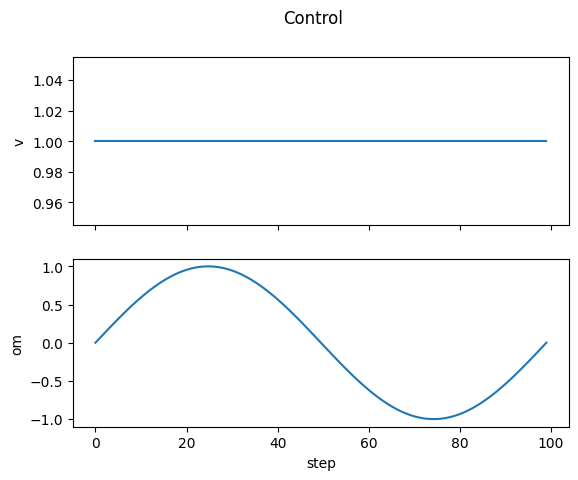

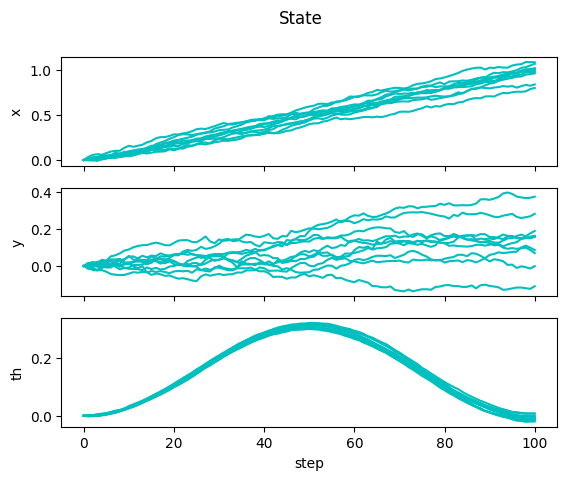

In [8]:
def plot_rollouts(control_traj, rollouts, ctrl_labels, state_labels):
    fig, axs = plt.subplots(nrows=len(ctrl_labels), sharex=True)
    for j, label in enumerate(ctrl_labels):
        axs[j].plot(control_traj[j, :])
        axs[j].set_ylabel(label)
    axs[-1].set_xlabel("step")
    fig.suptitle("Control")

    fig, axs = plt.subplots(nrows=len(state_labels), sharex=True)
    for i in range(rollouts.shape[0]):
        for j, label in enumerate(state_labels):
            axs[j].plot(rollouts[i, :, j], c='c')
            axs[j].set_ylabel(label)
    axs[-1].set_xlabel("step")
    fig.suptitle("State")
    plt.show()

plot_rollouts(control_traj, tb_rollouts, ["v", "om"], ["x", "y", "th"])

## Double Integrator Rollouts

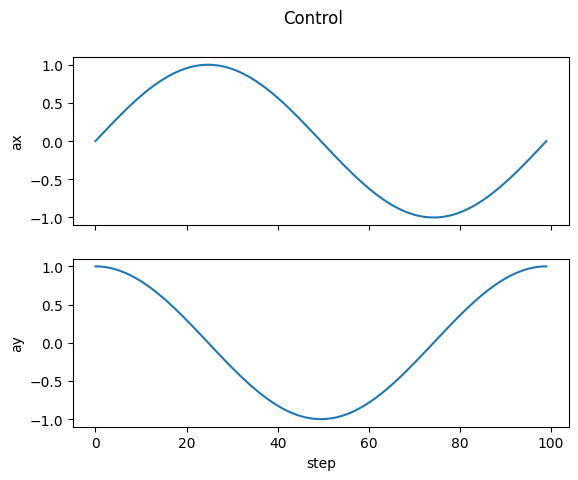

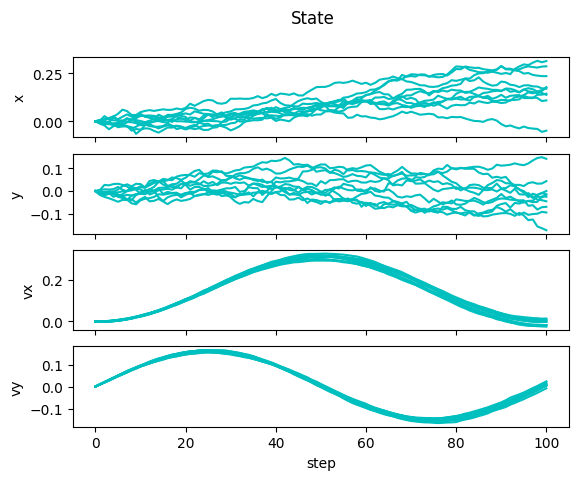

In [9]:
np.random.seed(SEED)

di_dynamics = DoubleIntegratorDynamics()

control_traj = np.zeros((di_dynamics.m, num_steps))
control_traj[0, :] = np.sin(np.linspace(0.0, 2 * np.pi, num_steps))
control_traj[1, :] = np.cos(np.linspace(0.0, 2 * np.pi, num_steps))

state_init = np.array([0.0, 0.0, 0.0, 0.0])
di_rollouts = di_dynamics.rollout(state_init, control_traj, num_rollouts)
assert di_rollouts.shape == (num_rollouts, num_steps + 1, di_dynamics.n)

plot_rollouts(control_traj, di_rollouts, ["ax", "ay"], ["x", "y", "vx", "vy"])

## Euler Integration Error
With the noise turned off, apply a constant acceleration $a_x = 1$ m/s$^2$ for $T = 1$ s, starting from rest. The exact final position is $x(T) = a_x T^2 / 2 = 0.5$ m. Use this cell for part (iii).

In [10]:
T_final = 1.0
for dt in [0.1, 0.01]:
    di = DoubleIntegratorDynamics(dt=dt, noisy=False)
    steps = int(round(T_final / dt))
    controls = np.tile([[1.0], [0.0]], (1, steps))
    x_final = di.rollout(np.zeros(4), controls, 1)[0, -1, 0]
    print(f"dt = {dt:5.2f}: Euler x(T) = {x_final:.4f}, exact = 0.5000, error = {0.5 - x_final:.4f}")

dt =  0.10: Euler x(T) = 0.4500, exact = 0.5000, error = 0.0500
dt =  0.01: Euler x(T) = 0.4950, exact = 0.5000, error = 0.0050
